In [1]:
import ast
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.patheffects as path_effects
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

DATA = Path("data")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
K = 21
N_SAMPLES = pd.read_csv(DATA / "datasets.csv").set_index("dataset")["n_samples"].to_dict()


def save_figure(fig, name, **kwargs):
    fig.savefig(OUT / name, metadata={"CreationDate": None}, **kwargs)


def explode_recommendations(folder, threshold=0.5):
    rows = []
    for file in sorted(os.listdir(folder)):
        df = pd.read_csv(folder / file)
        pls = ast.literal_eval(df["pls"][0])
        dataset_name = df["dataset_name"][0]
        k, p = 1, 0
        for idx in range(len(pls)):
            p += 1
            if p >= 6:
                k, p = k + 1, 1
            best_ari = -1
            for pl in pls[: idx + 1]:
                if pl[3] <= k and pl[5] <= p and N_SAMPLES[dataset_name] * threshold < pl[6] and best_ari < pl[1]:
                    best_ari = pl[1]
            rows.append({"dataset_name": dataset_name, "ari_before": df["ari_before"][0],
                         "best_ari": best_ari, "k": k, "nr_pipelines": p})
    return pd.DataFrame(rows)


exploded = {alg: explode_recommendations(DATA / f"prepmatch_{alg}")
            for alg in ["dbscan", "hdbscan", "agglomerative", "kmeans"]}

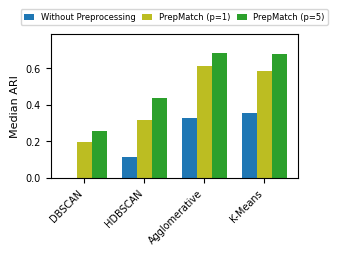

In [2]:
labels = {"dbscan": "DBSCAN", "hdbscan": "HDBSCAN", "agglomerative": "Agglomerative", "kmeans": "K-Means"}
medians = []
for alg, df in exploded.items():
    df = df[df["k"] == K]
    medians.append({
        "algorithm": labels[alg],
        "ari_before": df.groupby("dataset_name")["ari_before"].first().median(),
        "p1": df.loc[df["nr_pipelines"] == 1, "best_ari"].median(),
        "p5": df.loc[df["nr_pipelines"] == 5, "best_ari"].median(),
    })
medians = pd.DataFrame(medians)

colors = plt.get_cmap("tab10").colors
bar_width = 0.25
indices = np.arange(len(medians))
fig, ax = plt.subplots(figsize=(3.4, 2.8))
ax.bar(indices - bar_width, medians["ari_before"], bar_width, label="Without Preprocessing")
ax.bar(indices, medians["p1"], bar_width, label="PrepMatch (p=1)", color=colors[8])
ax.bar(indices + bar_width, medians["p5"], bar_width, label="PrepMatch (p=5)", color=colors[2])
ax.set_xticks(indices)
ax.set_xticklabels(medians["algorithm"], rotation=45, ha="right", fontsize=7)
ax.tick_params(axis="y", labelsize=7)
ax.set_ylabel("Median ARI", fontsize=8)
ax.set_ylim(0, medians[["ari_before", "p1", "p5"]].max().max() * 1.15)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=3, fontsize=6, frameon=True,
          columnspacing=0.8, handlelength=1.2)
fig.tight_layout()
save_figure(fig, "all_algorithms_median_bars4.pdf", bbox_inches="tight")
plt.show()

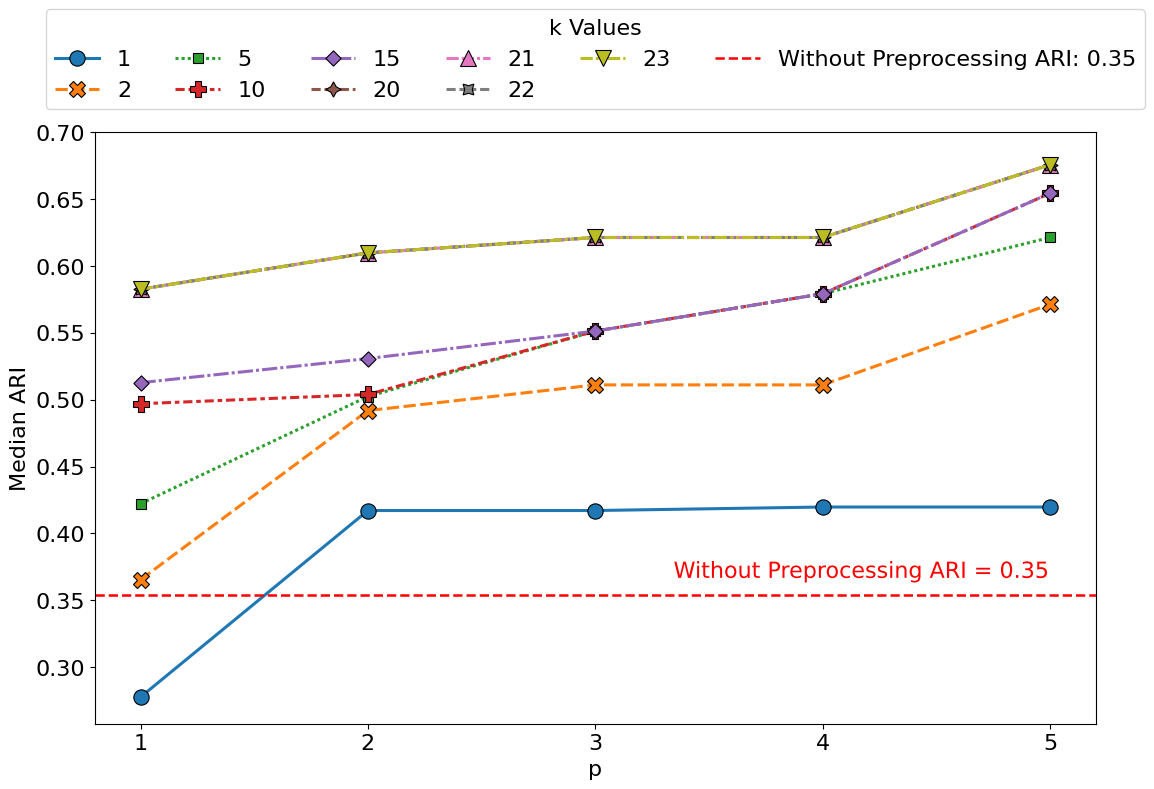

In [3]:
k_values = [1, 2, 5, 10, 15, 20, 21, 22, 23]
df = exploded["kmeans"]
df = df[df["k"].isin(k_values)].rename(columns={"nr_pipelines": "p"})
baseline = df[["dataset_name", "ari_before"]].drop_duplicates()["ari_before"].median()
median_scores = df.groupby(["p", "k"])["best_ari"].median().reset_index()

fontsize = 16
fig = plt.figure(figsize=(12, 8))
ax = sns.lineplot(data=median_scores, x="p", y="best_ari", hue="k", style="k", markers=True, dashes=True,
                  palette=sns.color_palette("tab10", n_colors=len(k_values)), linewidth=2.2, markersize=11, alpha=1)
for line in ax.lines:
    line.set_markeredgecolor("black")
    line.set_markeredgewidth(0.8)
plt.axhline(y=baseline, color="red", linestyle="--", linewidth=1.8, label=f"Without Preprocessing ARI: {baseline:.2f}")
txt = plt.text(median_scores["p"].max(), baseline + 0.01, f"Without Preprocessing ARI = {baseline:0.2f}",
               color="red", ha="right", va="bottom", fontsize=fontsize)
txt.set_path_effects([path_effects.Stroke(linewidth=3, foreground="white"), path_effects.Normal()])
plt.xlabel("p", fontsize=fontsize)
plt.ylabel("Median ARI", fontsize=fontsize)
plt.tick_params(axis="both", which="major", labelsize=fontsize)
plt.ylim(plt.gca().get_ylim()[0], 0.7)
plt.legend(title="k Values", loc="lower center", fontsize=fontsize, title_fontsize=fontsize,
           bbox_to_anchor=(0.5, 1.02), ncol=6)
ax.set_xticks(sorted(median_scores["p"].unique()))
plt.tight_layout()
save_figure(fig, "k_p_comb3.pdf")
plt.show()

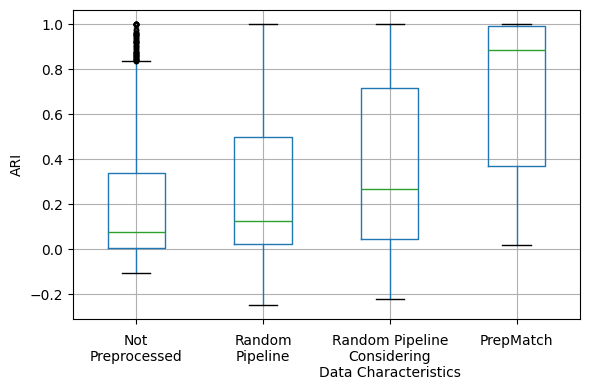

In [4]:
kb = pd.read_csv(DATA / "kb_results.csv")
random_baselines = pd.read_csv(DATA / "random_baselines.csv")
files = ["m_2", "mo_2", "ms_2", "mso_2", "s", "o", "so"]
res = pd.concat([
    pd.concat([kb.loc[kb["file"] == f, "modified_ari"] for f in files], ignore_index=True),
    random_baselines["random_score"],
    random_baselines["random_group_score"],
    pd.concat([kb.loc[kb["file"] == f, "best_fitness"] for f in files], ignore_index=True),
], axis=1, keys=["not_preprocessed", "random", "random_group", "prepmatch"])

mpl.rcdefaults()
plt.figure(figsize=(6, 4))
bp = res.boxplot(list(res.columns), return_type="dict")
for flier in bp["fliers"]:
    flier.set(marker="o", markersize=3, alpha=0.4)
ax = plt.gca()
ax.set_xticklabels([""] * 4)
top_labels = ["Not", "Random", "Random Pipeline", "PrepMatch"]
bottom_labels = ["Preprocessed", "Pipeline", "Considering\nData Characteristics", ""]
for x, top, bottom in zip([1, 2, 3, 4], top_labels, bottom_labels):
    ax.text(x, -0.05, top, ha="center", va="top", transform=ax.get_xaxis_transform())
    if bottom:
        ax.text(x, -0.1, bottom, ha="center", va="top", transform=ax.get_xaxis_transform())
plt.ylabel("ARI")
plt.tight_layout()
save_figure(plt.gcf(), "baselines_small_5.pdf")
plt.show()

In [5]:
def fmt(v):
    if pd.isna(v):
        return "-"
    s = f"{v:.2f}"
    return "0.00" if s == "-0.00" else s


rs = pd.read_csv(DATA / "random_search.csv").groupby("dataset_name")[["ari_before", "best_ari"]].mean()
tpe = pd.read_csv(DATA / "tpe_autoclust.csv").groupby("dataset_name")["score"].max()
tpot = pd.read_csv(DATA / "tpot_clustering.csv").set_index("dataset_name")["adjusted_rand_index"]
prepmatch = {alg: df[(df["k"] == K) & (df["nr_pipelines"] == 5)].set_index("dataset_name")["best_ari"]
             for alg, df in exploded.items()}
table = pd.DataFrame({"no_prep": rs["ari_before"], "random": rs["best_ari"], "tpot": tpot, "tpe": tpe,
                      **prepmatch}).sort_index().round(2)
table["best"] = table[list(prepmatch)].max(axis=1)

compared = ["no_prep", "random", "tpot", "tpe", "kmeans"]
lines = [
    r"\begin{tabular}{lccccc|c}",
    r"\toprule",
    r" &  &  &  &  & \multicolumn{2}{c}{PrepMatch (k=21, p=5)} \\",
    r"\cmidrule(lr){6-7}",
    r"Dataset & No Preprocessing & Random Search & TPOT-Clustering & TPE-AutoClust & KMeans & Best across algorithms \\",
    r"\midrule",
]
for dataset, row in table.iterrows():
    best_compared = row[compared].max()
    cells = [rf"\underline{{{fmt(row[c])}}}" if row[c] == best_compared else fmt(row[c]) for c in compared]
    cells.append(rf"\textbf{{{fmt(row['best'])}}}" if row["best"] == row[compared + ["best"]].max() else fmt(row["best"]))
    lines.append(dataset.replace("_", r"\_") + " & " + " & ".join(cells) + r" \\")
lines += [r"\midrule", "Median & " + " & ".join(fmt(table[c].median()) for c in compared + ["best"]) + r" \\",
          r"\bottomrule", r"\end{tabular}"]
with open(OUT / "tab_baselines.tex", "w") as f:
    f.write("\n".join(lines) + "\n")

In [6]:
medians = kb.groupby("file")[["modified_ari", "best_fitness"]].median()
rows = [("N", "b", "b"), ("M", "m_1", "m_2"), ("D", "s", "s"), ("O", "o", "o"), ("M+D", "ms_1", "ms_2"),
        ("M+O", "mo_1", "mo_2"), ("D+O", "so", "so"), ("M+D+O", "mso_1", "mso_2")]
lines = [
    r"\begin{tabular}{l c c c}",
    r"\toprule",
    r"\makecell{Data \\ Characteristics} & \makecell{Before \\ Preprocessing} & "
    r"\makecell{\makecell{Missing Value \\ Imputation}} & \makecell{After \\ Preprocessing} \\",
    r"\midrule",
]
for name, first, after in rows:
    imputation = fmt(medians.loc[first, "best_fitness"]) if first != after else "-"
    lines.append(f"{name} & {fmt(medians.loc[first, 'modified_ari'])} & {imputation} & "
                 f"{fmt(medians.loc[after, 'best_fitness'])} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
with open(OUT / "tab_ppevalgroups.tex", "w") as f:
    f.write("\n".join(lines) + "\n")